In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler,LabelEncoder
from sklearn.metrics import accuracy_score,classification_report,f1_score,recall_score,precision_score

In [ ]:
df=pd.read_csv("/content/student_performance_data.csv")

In [ ]:
df.shape

(100000, 44)

In [ ]:
df.columns

Index(['student_id', 'age', 'gender', 'education_level', 'school_type',
       'family_income', 'parent_education', 'urban_rural',
       'previous_exam_score', 'previous_gpa', 'attendance_percentage',
       'assignment_completion_rate', 'class_participation',
       'study_hours_per_day', 'self_study_hours', 'private_tuition',
       'online_learning_hours', 'study_consistency', 'study_environment',
       'study_method', 'revision_frequency', 'practice_tests_completed',
       'notes_quality', 'sleep_hours', 'sleep_quality', 'daily_screen_time',
       'physical_activity_hours', 'break_frequency', 'stress_level',
       'motivation_level', 'internet_access', 'device_availability',
       'educational_app_usage', 'online_course_hours', 'exam_difficulty',
       'exam_preparation_days', 'questions_attempted', 'questions_correct',
       'time_management_score', 'exam_anxiety_level', 'exam_score',
       'performance_grade', 'pass_status', 'performance_level'],
      dtype='object')

In [ ]:
#DROPPING IDENTIFIERS & DATA LEAKAGE COLUMNS
df=df.drop(columns=['student_id','questions_correct','exam_score','performance_grade','performance_level'])

In [ ]:
df.dtypes

,0
age,int64
gender,object
education_level,object
school_type,object
family_income,object
parent_education,object
urban_rural,object
previous_exam_score,float64
previous_gpa,float64
attendance_percentage,float64


In [ ]:
df.isna().sum()

,0
age,0
gender,0
education_level,0
school_type,0
family_income,0
parent_education,6526
urban_rural,0
previous_exam_score,0
previous_gpa,7793
attendance_percentage,9863


In [ ]:
#MISSING VALUES HANDLING

In [ ]:
print(df['parent_education'].value_counts())
df['parent_education']=df['parent_education'].fillna(df['parent_education'].mode()[0])

parent_education
High School    28122
Bachelor       27943
Associate      18640
Master         14043
Doctorate       4726
Name: count, dtype: int64


In [ ]:
print(df['previous_gpa'].unique())
df['previous_gpa']=df['previous_gpa'].fillna(df['previous_gpa'].median())

[2.95 2.89 3.35 2.57 2.84  nan 3.   3.63 2.43 2.72 2.86 3.85 3.14 2.64
 2.7  1.83 3.12 2.03 3.52 2.88 2.66 2.42 2.8  3.58 4.   3.66 2.99 3.34
 2.08 2.74 3.5  3.15 3.3  2.25 2.01 3.74 2.19 2.83 1.8  2.59 2.28 1.68
 2.61 2.4  2.98 2.96 2.49 2.85 2.71 3.29 2.12 1.23 2.97 2.29 2.87 2.55
 2.56 2.41 3.26 1.93 3.39 3.08 3.04 1.73 2.68 2.6  2.65 2.52 3.65 2.24
 3.2  2.3  2.9  2.5  2.48 2.46 3.42 3.38 1.34 2.34 1.99 3.06 2.47 3.13
 3.18 3.17 2.73 3.61 2.35 2.76 2.1  3.94 3.27 2.78 2.77 2.21 2.91 3.11
 2.81 2.62 2.27 3.03 3.02 2.36 1.7  1.89 3.92 2.63 2.13 3.51 1.78 2.16
 3.8  3.37 3.4  3.57 3.41 1.58 3.53 2.33 3.05 3.31 3.22 3.59 3.79 3.1
 2.75 2.54 3.28 1.49 2.82 3.21 3.46 2.79 1.86 2.38 3.32 2.15 2.94 3.45
 2.45 2.44 1.87 3.56 2.11 2.58 1.55 2.92 1.98 2.69 3.93 2.51 3.49 3.9
 3.67 3.73 3.54 3.83 3.81 3.62 3.16 2.32 1.74 2.39 1.65 2.04 3.07 3.69
 2.23 2.53 3.68 1.91 2.05 3.33 2.31 3.23 3.24 3.25 2.2  1.97 3.47 3.72
 1.54 2.93 1.85 1.76 2.22 1.84 1.82 2.09 2.06 1.35 3.75 3.48 2.14 2.17
 2.37 1.

In [ ]:
print(df['attendance_percentage'].unique())
df['attendance_percentage']=df['attendance_percentage'].fillna(df['attendance_percentage'].mean())

[ 81.49    nan 100.   ...  55.37  61.15  64.91]


In [ ]:
print(df['notes_quality'].value_counts())
df['notes_quality']=df['notes_quality'].fillna(df['notes_quality'].mode()[0])

notes_quality
Average      54973
Excellent    18390
Poor         18230
Name: count, dtype: int64


In [ ]:
print(df['sleep_quality'].value_counts())
df['sleep_quality']=df['sleep_quality'].fillna(df['sleep_quality'].mode()[0])

sleep_quality
Fair         32439
Good         32380
Excellent    14134
Poor         14053
Name: count, dtype: int64


In [ ]:
print(df['device_availability'].value_counts())
df['device_availability']=df['device_availability'].fillna(df['device_availability'].mode()[0])

device_availability
Dedicated    71862
Shared       25173
Name: count, dtype: int64


In [ ]:
print(df['time_management_score'].unique())
df['time_management_score']=df['time_management_score'].fillna(df['time_management_score'].mean())

[  nan 87.17 63.77 ... 44.47 37.43 32.11]


In [ ]:
df.isna().sum()

,0
age,0
gender,0
education_level,0
school_type,0
family_income,0
parent_education,0
urban_rural,0
previous_exam_score,0
previous_gpa,0
attendance_percentage,0


In [ ]:
df['pass_status'].value_counts()

,count
pass_status,
Pass,77389
Fail,22611


In [ ]:
#LABEL ENCODING

In [ ]:
encoder=LabelEncoder()
obj_cols = df.select_dtypes(include=['object']).columns
for col in obj_cols:
  df[col]=encoder.fit_transform(df[col])

In [ ]:
x=df.drop(columns='pass_status')

In [ ]:
x.shape

(100000, 38)

In [ ]:
y=df['pass_status']

In [ ]:
y.shape

(100000,)

In [ ]:
#SPLITTING TO TRAIN AND TEST DATA

In [ ]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.20,random_state=42,stratify=y)

In [ ]:
y_train.value_counts()

,count
pass_status,
1,61911
0,18089


In [ ]:
#BALANCING
from imblearn.over_sampling import SMOTE
smote=SMOTE(random_state=42)
x_train_res,y_train_res=smote.fit_resample(x_train,y_train)

In [ ]:
y_train_res.value_counts()


,count
pass_status,
1,61911
0,61911


In [ ]:
#FEATURE SCALING(Essential for Logistic Regression, Naive Bayes, and KNN)

In [ ]:
scaler=StandardScaler()
x_train_scaled=scaler.fit_transform(x_train_res)
x_test_scaled=scaler.transform(x_test)

In [ ]:
#MODEL CREATION

In [ ]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000,random_state=42),
    "Naive Bayes": GaussianNB(),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5, n_jobs=-1),
    "Decision Tree": DecisionTreeClassifier(max_depth=8, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=12, random_state=42)
}

In [ ]:
results = []
print("TRAINING 5 MODELS ")

for name, model in models.items():
    if name in ["Logistic Regression", "Naive Bayes", "K-Nearest Neighbors"]:
        model.fit(x_train_scaled, y_train_res)
        y_pred = model.predict(x_test_scaled)
    else:
        model.fit(x_train_res, y_train_res)
        preds = model.predict(x_test)

    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average='weighted')
    prec = precision_score(y_test, y_pred, average='weighted')
    rec = recall_score(y_test, y_pred, average='weighted')

    results.append({
        "Model": name,
        "Accuracy (%)": round(acc * 100, 2),
        "F1-Score": round(f1, 4),
        "Precision": round(prec, 4),
        "Recall": round(rec, 4)
    })



TRAINING 5 MODELS 


In [ ]:
# Display Summary Comparison Table
results_df = pd.DataFrame(results)
display(results_df)

,Model,Accuracy (%),F1-Score,Precision,Recall
0,Logistic Regression,77.67,0.7849,0.7982,0.7767
1,Naive Bayes,74.95,0.7594,0.7751,0.7495
2,K-Nearest Neighbors,66.04,0.6876,0.7680,0.6604
3,Decision Tree,66.04,0.6876,0.7680,0.6604
4,Random Forest,66.04,0.6876,0.7680,0.6604


In [ ]:
#VISUALISATION

/tmp/ipykernel_2473/1402814154.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


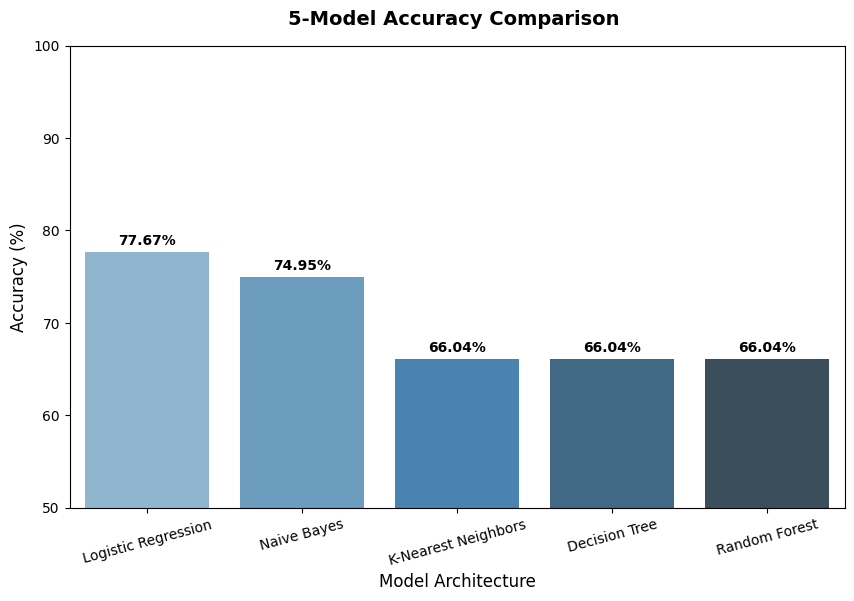

In [ ]:
plt.figure(figsize=(10,6))
ax = sns.barplot(
    data=results_df,
    x="Model",
    y="Accuracy (%)",
    palette="Blues_d"
)

#titles and axis labels
plt.title("5-Model Accuracy Comparison ", fontsize=14, fontweight="bold", pad=15)
plt.ylabel("Accuracy (%)", fontsize=12)
plt.xlabel("Model Architecture", fontsize=12)
plt.ylim(50, 100)
plt.xticks(rotation=15, fontsize=10)

for c in ax.containers:
    ax.bar_label(c, fmt='%.2f%%', padding=3, fontweight='bold')

plt.show()

In [ ]:
#CHOOSING LOGISTIC REGRESSION

In [ ]:
#HYPER PARAMETER TUNING
from sklearn.model_selection import GridSearchCV
model=LogisticRegression(max_iter=1000,random_state=42)
param_grid={
        'solver': ['lbfgs', 'newton-cg', 'sag'],
        'penalty': ['l2'],
        'C': [0.001, 0.01, 0.1, 1, 10, 100],
        'max_iter': [100, 500, 1000]}
Grid=GridSearchCV(model,param_grid,cv=3,scoring='accuracy')
Grid.fit(x_train_scaled,y_train_res)

GridSearchCV(cv=3, estimator=LogisticRegression(max_iter=1000, random_state=42),
             param_grid={'C': [0.001, 0.01, 0.1, 1, 10, 100],
                         'max_iter': [100, 500, 1000], 'penalty': ['l2'],
                         'solver': ['lbfgs', 'newton-cg', 'sag']},
             scoring='accuracy')

In [ ]:
best_model=Grid.best_estimator_
best_model

LogisticRegression(C=0.001, random_state=42, solver='sag')

In [ ]:
Grid.best_score_

np.float64(0.7999063171326583)

In [ ]:
#FEATURE SELECTION-BEST 5 FEATURE

feature_names = x_train.columns
coefficients = np.abs(best_model.coef_[0])

# Rank them by importance
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': coefficients
}).sort_values(by='Importance', ascending=False)

# Select the top 5 feature names
top_5_features = importance_df['Feature'].head(5).tolist()
print("Top 5 Features:", top_5_features)

Top 5 Features: ['previous_exam_score', 'practice_tests_completed', 'exam_preparation_days', 'study_hours_per_day', 'attendance_percentage']


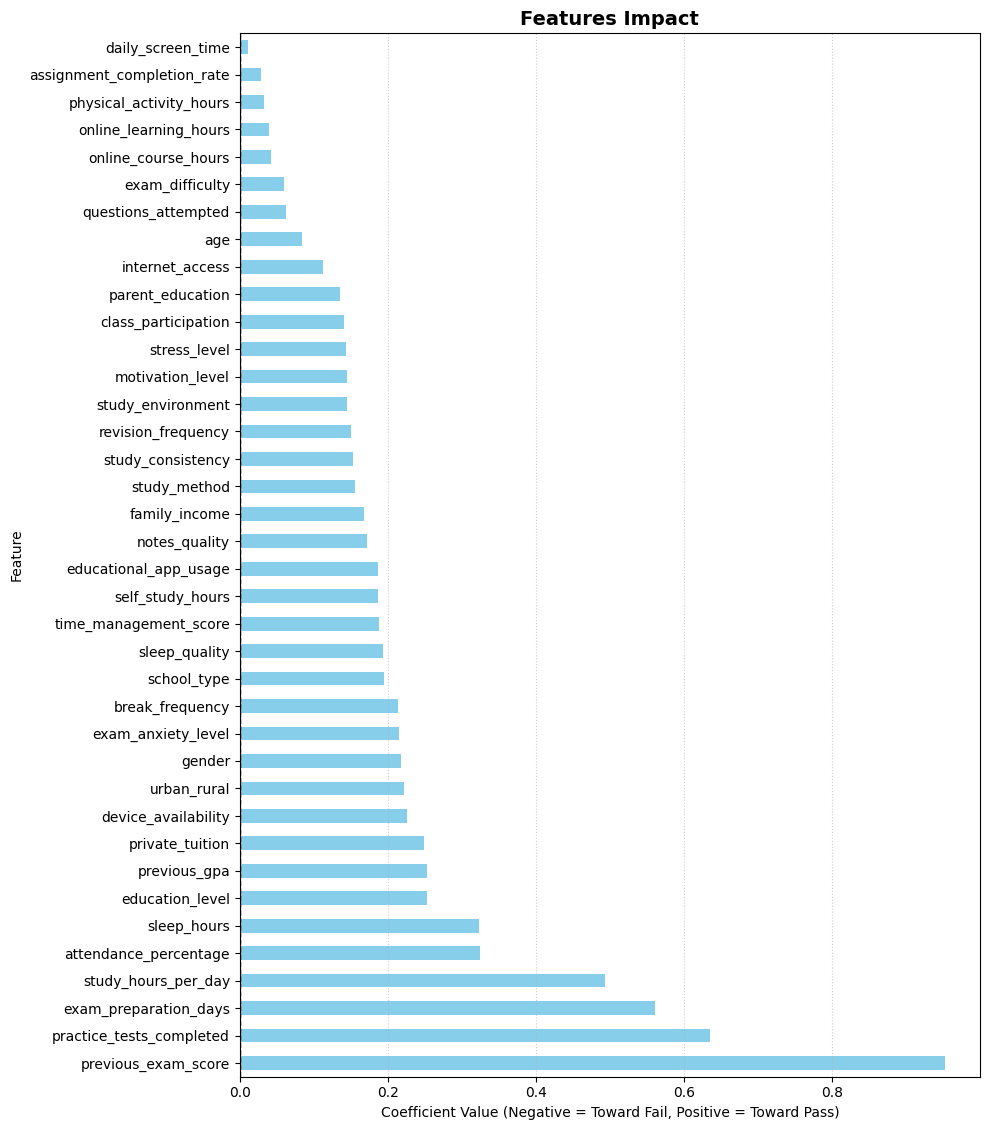

In [ ]:
plt.figure(figsize=(10, max(6, len(x_train.columns) * 0.3)))  # Dynamically sizes so labels don't bunch up
importance_df.set_index('Feature')['Importance'].plot(kind='barh', color='skyblue')

plt.title('Features Impact', fontsize=14, fontweight='bold')
plt.xlabel('Coefficient Value (Negative = Toward Fail, Positive = Toward Pass)')
plt.axvline(x=0, color='black', linestyle='--', linewidth=1)
plt.grid(axis='x', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
print(df['previous_exam_score'].min())
print(df['previous_exam_score'].max())

30.0
100.0


In [ ]:
print(df['practice_tests_completed'].min())
print(df['practice_tests_completed'].max())

0
20


In [ ]:
print(df['exam_preparation_days'].min())
print(df['exam_preparation_days'].max())

1
30


In [ ]:
print(df['study_hours_per_day'].min())
print(df['study_hours_per_day'].max())

0.5
12.0


In [ ]:
st_x_train=x_train_res[top_5_features]
st_x_test=x_test[top_5_features]
#scaling
scaler_top5=StandardScaler()
st_x_train_scaled=scaler_top5.fit_transform(st_x_train)
st_x_test_scaled=scaler_top5.transform(st_x_test)


In [ ]:
streamlit_model=LogisticRegression(C=0.001, random_state=42, solver='sag')
streamlit_model.fit(st_x_train_scaled,y_train_res)


LogisticRegression(C=0.001, random_state=42, solver='sag')

In [ ]:
#STREAMLIT
import joblib
joblib.dump(streamlit_model,"streamlit_model.pkl")
joblib.dump(scaler_top5,"Scaler.pkl")

['Scaler.pkl']

In [ ]:
X_test_top5 = x_test[['previous_exam_score', 'practice_tests_completed', 'exam_preparation_days', 'study_hours_per_day', 'attendance_percentage']]

# Scale the 5 features
X_test_scaled_5 = scaler_top5.transform(X_test_top5)

# Compare model predictions against the true answers (y_test)
y_pred = streamlit_model.predict(X_test_scaled_5)
accuracy = accuracy_score(y_test, y_pred)
print(accuracy)

0.7481
